## DLP ASS # 2 --------------23F-0599

In [57]:
print("Hello World")

Hello World


## Part A

In [67]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [59]:
CACHE = '/kaggle/working/cifar10.npz'
if os.path.exists(CACHE):
    d = np.load(CACHE)
    x_full, y_full, x_test, y_test = d['a'], d['b'], d['c'], d['d']
else:
    (x_full, y_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
    np.savez_compressed(CACHE, a=x_full, b=y_full.flatten(), c=x_test, d=y_test.flatten())
    y_full, y_test = y_full.flatten(), y_test.flatten()

x_full = x_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
y_full, y_test = y_full.flatten(), y_test.flatten()
print(x_full.shape, x_test.shape)

(50000, 32, 32, 3) (10000, 32, 32, 3)


In [71]:
rng = np.random.default_rng(SEED)
tr_idx, val_idx = [], []
for c in range(10):
    idx = rng.choice(np.where(y_full == c)[0], 50, replace=False)
    tr_idx += list(idx[:40])    # 40 per class = 400 train
    val_idx += list(idx[40:])   # 10 per class = 100 val

x_tr,  y_tr  = x_full[tr_idx],  y_full[tr_idx]
x_val, y_val = x_full[val_idx], y_full[val_idx]
print("Train:", x_tr.shape, "| Val:", x_val.shape)

Train: (400, 32, 32, 3) | Val: (100, 32, 32, 3)


In [72]:
def make_shifted_test(images, seed=123):
    rng = np.random.default_rng(seed)
    n = len(images)

    # rotation up to ±25°, brightness, contrast (random per image)
    imgs = layers.RandomRotation(25/360, fill_mode='reflect', seed=seed)(images, training=True)
    imgs = layers.RandomBrightness(0.2, value_range=(0, 1), seed=seed)(imgs, training=True)
    imgs = layers.RandomContrast(0.3, value_range=(0, 1), seed=seed)(imgs, training=True).numpy()

    # 16x16 occlusion (25% of the image)
    for i in range(n):
        y0, x0 = rng.integers(0, 17, 2)
        imgs[i, y0:y0+16, x0:x0+16] = 0

    # hidden corruption: random grayscale on half of the images
    gray = np.repeat(imgs.mean(-1, keepdims=True), 3, -1)
    mask = rng.random(n) < 0.5
    imgs[mask] = gray[mask]

    return imgs.astype('float32')

x_shifted = make_shifted_test(x_test)
print("shifted_test:", x_shifted.shape)

shifted_test: (10000, 32, 32, 3)


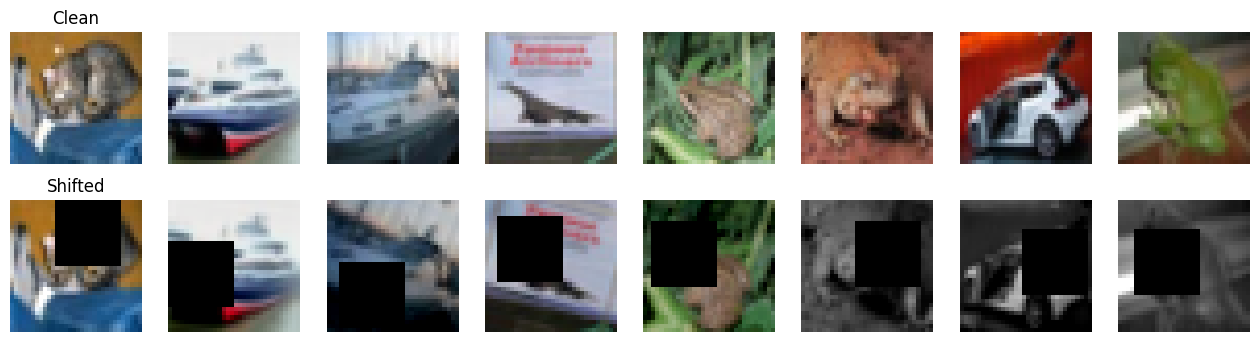

In [73]:
fig, ax = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    ax[0, i].imshow(x_test[i]);    ax[0, i].axis('off')
    ax[1, i].imshow(x_shifted[i]); ax[1, i].axis('off')
ax[0, 0].set_title("Clean"); ax[1, 0].set_title("Shifted")
plt.show()

In [74]:
def conv_bn(x, filters, k):
    x = layers.Conv2D(filters, k, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)

def inception_block(x, f1, f3r, f3, f5r, f5, fp):
    b1 = conv_bn(x, f1, 1)
    b2 = conv_bn(conv_bn(x, f3r, 1), f3, 3)
    b3 = conv_bn(conv_bn(x, f5r, 1), f5, 5)
    b4 = layers.MaxPooling2D(3, strides=1, padding='same')(x)
    b4 = conv_bn(b4, fp, 1)
    return layers.Concatenate()([b1, b2, b3, b4])

In [75]:
def build_model():
    inp = layers.Input((32, 32, 3))
    x = layers.Rescaling(2.0, offset=-1.0)(inp)   
    x = conv_bn(x, 32, 3)
    x = conv_bn(x, 32, 3)
    x = layers.MaxPooling2D()(x)
    x = inception_block(x, 32, 32, 48, 8, 16, 16)
    x = layers.MaxPooling2D()(x)
    x = inception_block(x, 48, 48, 64, 12, 32, 32)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(10, activation='softmax')(x)
    return keras.Model(inp, out)

model = build_model()
trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print("Trainable params:", trainable, "(limit 1,000,000)")

Trainable params: 85522 (limit 1,000,000)


In [76]:
results = {'Train': [], 'Val': [], 'Clean Test': [], 'Shifted Test': []}
histories = []

for seed in [42, 43, 44]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    model = build_model()
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h = model.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                  epochs=60, batch_size=16, verbose=0)

    results['Train'].append(model.evaluate(x_tr, y_tr, verbose=0)[1])
    results['Val'].append(model.evaluate(x_val, y_val, verbose=0)[1])
    results['Clean Test'].append(model.evaluate(x_test, y_test, verbose=0)[1])
    results['Shifted Test'].append(model.evaluate(x_shifted, y_test, verbose=0)[1])
    histories.append(h.history)

    print(f"seed {seed}:", {k: round(v[-1]*100, 1) for k, v in results.items()})

seed 42: {'Train': 99.8, 'Val': 50.0, 'Clean Test': 42.0, 'Shifted Test': 20.1}
seed 43: {'Train': 99.5, 'Val': 40.0, 'Clean Test': 41.4, 'Shifted Test': 20.6}
seed 44: {'Train': 99.8, 'Val': 40.0, 'Clean Test': 42.6, 'Shifted Test': 22.9}


,Train,Val,Clean Test,Shifted Test
Baseline (no aug),99.67 ± 0.12,43.33 ± 4.71,42.00 ± 0.49,21.18 ± 1.21


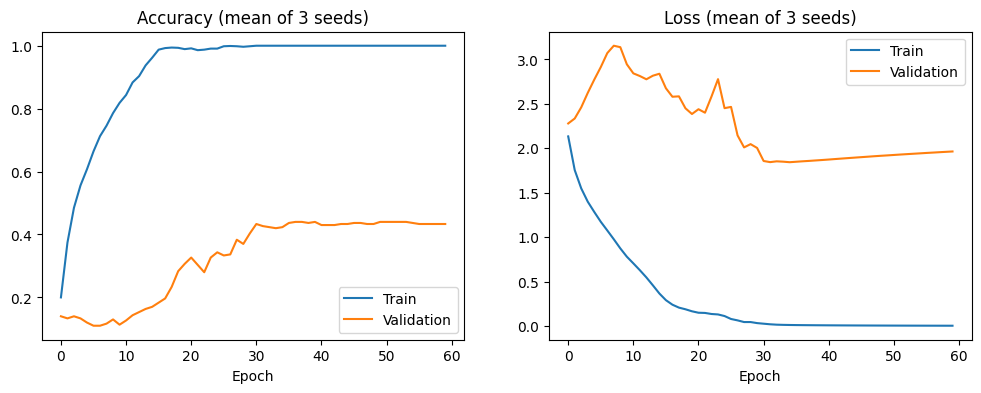

In [77]:
table = pd.DataFrame({k: [f"{np.mean(v)*100:.2f} ± {np.std(v)*100:.2f}"] for k, v in results.items()},
                     index=['Baseline (no aug)'])
display(table)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for key, label in [('accuracy', 'Train'), ('val_accuracy', 'Validation')]:
    ax[0].plot(np.mean([h[key] for h in histories], axis=0), label=label)
for key, label in [('loss', 'Train'), ('val_loss', 'Validation')]:
    ax[1].plot(np.mean([h[key] for h in histories], axis=0), label=label)
ax[0].set_title('Accuracy (mean of 3 seeds)'); ax[1].set_title('Loss (mean of 3 seeds)')
for a in ax: a.set_xlabel('Epoch'); a.legend()
plt.show()

The model reaches near-perfect accuracy on the training data but much lower accuracy on validation, showing clear overfitting: with just 400 images the network memorises them instead of learning general features. Clean-test accuracy is close to validation accuracy, so overfitting is not the whole story. Accuracy on the shifted test set drops much further, which is a separate failure, because the shifted images are rotated, brightness/contrast-changed, occluded and partly grayscaled in ways the model never saw during training. The gap between clean-test and shifted-test accuracy is therefore the signature of covariate shift, while the gap between training and validation accuracy is the signature of overfitting. Both problems are present.

## Part B

In [89]:
# Built-in Keras augmentation layers (created once)
flip      = layers.RandomFlip("horizontal")
rotate    = layers.RandomRotation(25/360, fill_mode='reflect')
shift     = layers.RandomTranslation(0.08, 0.08, fill_mode='reflect')
bright    = layers.RandomBrightness(0.2, value_range=(0, 1))
contrast  = layers.RandomContrast(0.2, value_range=(0, 1))

def augment(x, y):
    # geometric
    x = flip(x, training=True)
    x = rotate(x, training=True)
    x = shift(x, training=True)

    # photometric
    x = bright(x, training=True)
    x = contrast(x, training=True)

    # random grayscale on 20% of images
    b = tf.shape(x)[0]
    gray = tf.reduce_mean(x, axis=-1, keepdims=True) * tf.ones_like(x)
    x = tf.where(tf.random.uniform([b, 1, 1, 1]) < 0.5, gray, x)

    # cutout: 10x10 black box on 30% of images
    y0 = tf.random.uniform([b, 1, 1], 0, 22, dtype=tf.int32)
    x0 = tf.random.uniform([b, 1, 1], 0, 22, dtype=tf.int32)
    r = tf.range(32)
    box = (r[None, :, None] >= y0) & (r[None, :, None] < y0 + 10) & \
          (r[None, None, :] >= x0) & (r[None, None, :] < x0 + 10)
    box = box & (tf.random.uniform([b, 1, 1]) < 0.3)
    x = tf.where(box[..., None], 0.0, x)

    return x, y

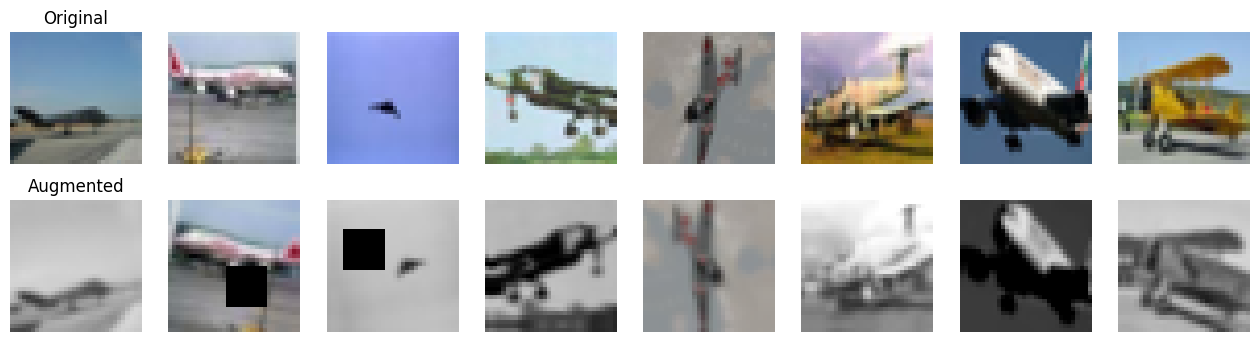

In [90]:
sample, _ = augment(x_tr[:8], y_tr[:8])
sample = np.clip(sample.numpy(), 0, 1)

fig, ax = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    ax[0, i].imshow(x_tr[i]); ax[0, i].axis('off')
    ax[1, i].imshow(sample[i]); ax[1, i].axis('off')
ax[0, 0].set_title("Original"); ax[1, 0].set_title("Augmented")
plt.show()

In [91]:
def build_model_aug(aug):
    inp = layers.Input((32, 32, 3))
    x = aug(inp)                                   # augmentation (training only)
    x = layers.Rescaling(2.0, offset=-1.0)(x)
    x = conv_bn(x, 32, 3)
    x = conv_bn(x, 32, 3)
    x = layers.MaxPooling2D()(x)
    x = inception_block(x, 32, 32, 48, 8, 16, 16)
    x = layers.MaxPooling2D()(x)
    x = inception_block(x, 48, 48, 64, 12, 32, 32)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(10, activation='softmax')(x)
    return keras.Model(inp, out)

m = build_model_aug(build_aug())
print("Trainable params:", int(sum(np.prod(w.shape) for w in m.trainable_weights)), "(limit 1,000,000)")

Trainable params: 85522 (limit 1,000,000)


In [94]:
results_aug = {'Train': [], 'Val': [], 'Clean Test': [], 'Shifted Test': []}
histories_aug = []

for seed in [42, 43, 44]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    model = build_model_aug(build_aug())
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h = model.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                  epochs=60, batch_size=16, verbose=0)

    results_aug['Train'].append(model.evaluate(x_tr, y_tr, verbose=0)[1])
    results_aug['Val'].append(model.evaluate(x_val, y_val, verbose=0)[1])
    results_aug['Clean Test'].append(model.evaluate(x_test, y_test, verbose=0)[1])
    results_aug['Shifted Test'].append(model.evaluate(x_shifted, y_test, verbose=0)[1])
    histories_aug.append(h.history)

    print(f"seed {seed}:", {k: round(v[-1]*100, 1) for k, v in results_aug.items()})

seed 42: {'Train': 43.0, 'Val': 32.0, 'Clean Test': 34.3, 'Shifted Test': 28.8}
seed 43: {'Train': 47.7, 'Val': 43.0, 'Clean Test': 37.2, 'Shifted Test': 31.8}
seed 44: {'Train': 54.8, 'Val': 47.0, 'Clean Test': 39.4, 'Shifted Test': 33.7}


,Train,Val,Clean Test,Shifted Test
Baseline (no aug),99.67 ± 0.12,43.33 ± 4.71,42.00 ± 0.49,21.18 ± 1.21
Geometric + photometric + cutout,48.50 ± 4.83,40.67 ± 6.34,36.99 ± 2.08,31.46 ± 2.01


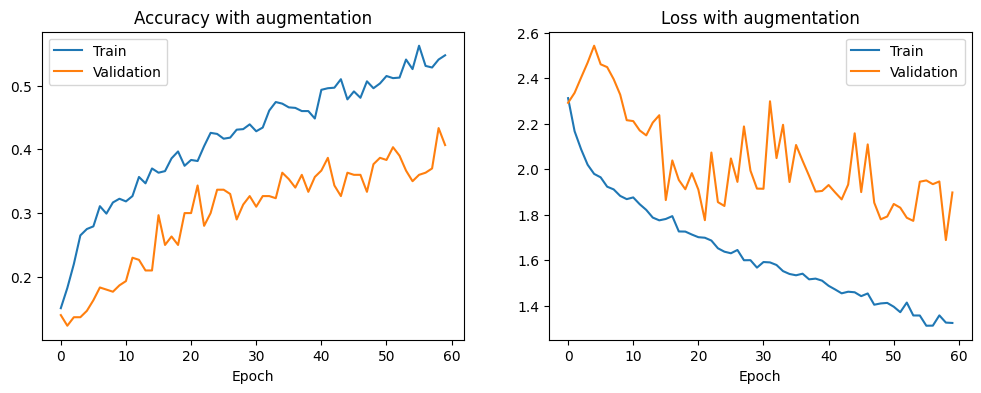

In [95]:
def fmt(r):
    return {k: f"{np.mean(v)*100:.2f} ± {np.std(v)*100:.2f}" for k, v in r.items()}

display(pd.DataFrame([fmt(results), fmt(results_aug)],
                     index=['Baseline (no aug)', 'Geometric + photometric + cutout']))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for key, label in [('accuracy', 'Train'), ('val_accuracy', 'Validation')]:
    ax[0].plot(np.mean([h[key] for h in histories_aug], axis=0), label=label)
for key, label in [('loss', 'Train'), ('val_loss', 'Validation')]:
    ax[1].plot(np.mean([h[key] for h in histories_aug], axis=0), label=label)
ax[0].set_title('Accuracy with augmentation'); ax[1].set_title('Loss with augmentation')
for a in ax: a.set_xlabel('Epoch'); a.legend()
plt.show()

## Part C

In [100]:
def build_model_c(dropout=0.3):
    inp = layers.Input((32, 32, 3))
    x = layers.Rescaling(2.0, offset=-1.0)(inp)
    x = conv_bn(x, 32, 3)
    x = conv_bn(x, 32, 3)
    x = layers.MaxPooling2D()(x)
    x = inception_block(x, 32, 32, 48, 8, 16, 16)
    x = layers.MaxPooling2D()(x)
    x = inception_block(x, 48, 48, 64, 12, 32, 32)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)          # only here, before the classifier
    out = layers.Dense(10, activation='softmax')(x)
    return keras.Model(inp, out)

In [101]:
m = build_model_c()
print("Trainable params:", int(sum(np.prod(w.shape) for w in m.trainable_weights)), "(limit 1,000,000)")

Trainable params: 85522 (limit 1,000,000)


In [102]:
EPOCHS, BATCH = 60, 16
STEPS_PER_EPOCH = 400 // BATCH      # 25

LR           = 1e-3    
WEIGHT_DECAY = 5e-4
SMOOTHING    = 0.1
PATIENCE     = 15

In [103]:
def make_train_data():
    data = tf.data.Dataset.from_tensor_slices((x_tr, y_tr))
    data = data.shuffle(400).batch(BATCH)
    data = data.map(augment)                                 
    data = data.map(lambda x, y: (x, tf.one_hot(y, 10)))      
    return data

val_data = (x_val, tf.one_hot(y_val, 10))

In [104]:
def make_optimizer():
    lr = keras.optimizers.schedules.CosineDecay(LR, EPOCHS * STEPS_PER_EPOCH)   # LR scheduling
    return keras.optimizers.AdamW(lr, weight_decay=WEIGHT_DECAY)                # weight decay

loss_fn = keras.losses.CategoricalCrossentropy(label_smoothing=SMOOTHING)      # label smoothing

def make_early_stop():
    return keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                         restore_best_weights=True)             # early stopping

In [105]:
def accuracy(model, x, y):
    return float((model.predict(x, batch_size=1000, verbose=0).argmax(1) == y).mean())

In [106]:
results_c = {'Train': [], 'Val': [], 'Clean Test': [], 'Shifted Test': []}
hist_c = []

for seed in [42, 43, 44]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    model = build_model_c()
    model.compile(optimizer=make_optimizer(), loss=loss_fn, metrics=['accuracy'])
    h = model.fit(make_train_data(), validation_data=val_data, epochs=EPOCHS,
                  callbacks=[make_early_stop()], verbose=0)

    results_c['Train'].append(accuracy(model, x_tr, y_tr))
    results_c['Val'].append(accuracy(model, x_val, y_val))
    results_c['Clean Test'].append(accuracy(model, x_test, y_test))
    results_c['Shifted Test'].append(accuracy(model, x_shifted, y_test))
    hist_c.append(h.history)
    print(f"seed {seed} (epochs run: {len(h.history['loss'])}):",
          {k: round(v[-1]*100, 1) for k, v in results_c.items()})

seed 42 (epochs run: 55): {'Train': 63.5, 'Val': 46.0, 'Clean Test': 43.5, 'Shifted Test': 34.1}
seed 43 (epochs run: 36): {'Train': 52.2, 'Val': 52.0, 'Clean Test': 39.9, 'Shifted Test': 29.8}
seed 44 (epochs run: 48): {'Train': 60.2, 'Val': 41.0, 'Clean Test': 41.3, 'Shifted Test': 31.3}


,Train,Val,Clean Test,Shifted Test
No augmentation,99.67 ± 0.12,43.33 ± 4.71,42.00 ± 0.49,21.18 ± 1.21
Augmentation only,48.50 ± 4.83,40.67 ± 6.34,36.99 ± 2.08,31.46 ± 2.01
Augmentation + regularization,58.67 ± 4.73,46.33 ± 4.50,41.55 ± 1.51,31.76 ± 1.79


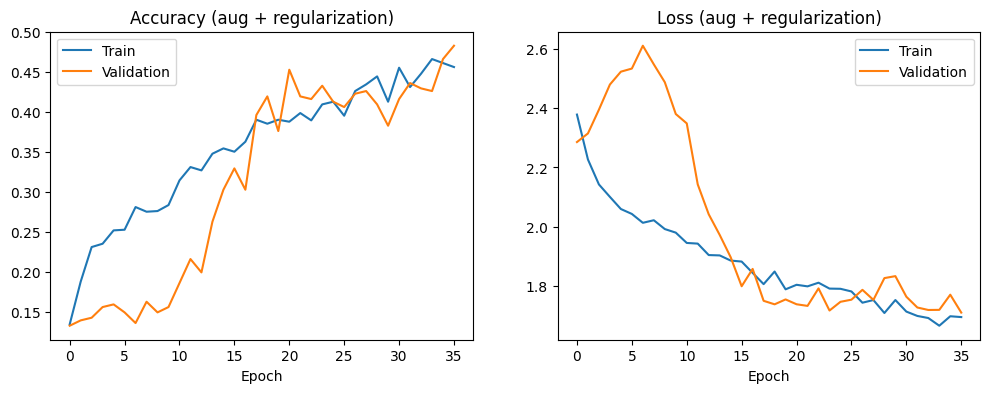

In [111]:
results_base = results
def fmt(r):
    return {k: f"{np.mean(v)*100:.2f} ± {np.std(v)*100:.2f}" for k, v in r.items()}

display(pd.DataFrame([fmt(results_base), fmt(results_aug), fmt(results_c)],
                     index=['No augmentation', 'Augmentation only', 'Augmentation + regularization']))

n = min(len(h['loss']) for h in hist_c)      # runs may stop at different epochs

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for key, label in [('accuracy', 'Train'), ('val_accuracy', 'Validation')]:
    ax[0].plot(np.mean([h[key][:n] for h in hist_c], axis=0), label=label)
for key, label in [('loss', 'Train'), ('val_loss', 'Validation')]:
    ax[1].plot(np.mean([h[key][:n] for h in hist_c], axis=0), label=label)
ax[0].set_title('Accuracy (aug + regularization)'); ax[1].set_title('Loss (aug + regularization)')
for a in ax: a.set_xlabel('Epoch'); a.legend()
plt.show()

## Part D

In [112]:
def geometric(x):
    x = flip(x, training=True)
    x = rotate(x, training=True)
    return shift(x, training=True)

def photometric(x):
    x = bright(x, training=True)
    x = contrast(x, training=True)
    b = tf.shape(x)[0]
    gray = tf.reduce_mean(x, axis=-1, keepdims=True) * tf.ones_like(x)
    return tf.where(tf.random.uniform([b, 1, 1, 1]) < 0.5, gray, x)     # 50% grayscale

def cutout(x):
    b = tf.shape(x)[0]
    y0 = tf.random.uniform([b, 1, 1], 0, 22, dtype=tf.int32)
    x0 = tf.random.uniform([b, 1, 1], 0, 22, dtype=tf.int32)
    r = tf.range(32)
    box = (r[None, :, None] >= y0) & (r[None, :, None] < y0 + 10) & \
          (r[None, None, :] >= x0) & (r[None, None, :] < x0 + 10)
    box = box & (tf.random.uniform([b, 1, 1]) < 0.3)
    return tf.where(box[..., None], 0.0, x)

def mixup(x, y, alpha=0.2):
    g1 = tf.random.gamma([], alpha)
    g2 = tf.random.gamma([], alpha)
    lam = g1 / (g1 + g2)                                   # Beta(alpha, alpha)
    x = lam * x + (1 - lam) * tf.reverse(x, [0])
    y = lam * y + (1 - lam) * tf.reverse(y, [0])
    return x, y

In [113]:
configs = {
    'No augmentation':               dict(geo=False, photo=False, cut=False, mix=False, smooth=0.0),
    'Geometric only':                dict(geo=True,  photo=False, cut=False, mix=False, smooth=0.0),
    'Photometric only':              dict(geo=False, photo=True,  cut=False, mix=False, smooth=0.0),
    'Geometric + photometric':       dict(geo=True,  photo=True,  cut=False, mix=False, smooth=0.0),
    '+ Cutout':                      dict(geo=True,  photo=True,  cut=True,  mix=False, smooth=0.0),
    '+ Mixup + label smoothing':     dict(geo=True,  photo=True,  cut=True,  mix=True,  smooth=0.1),
}
EPOCHS, BATCH = 60, 16

In [114]:
def make_data(cfg):
    data = tf.data.Dataset.from_tensor_slices((x_tr, y_tr)).shuffle(400).batch(BATCH)
    data = data.map(lambda x, y: (x, tf.one_hot(y, 10)))

    def augment_cfg(x, y):
        if cfg['geo']:   x = geometric(x)
        if cfg['photo']: x = photometric(x)
        if cfg['cut']:   x = cutout(x)
        if cfg['mix']:   x, y = mixup(x, y)
        return x, y

    return data.map(augment_cfg)

In [115]:
def train_one(cfg, seed, final=False):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    lr = keras.optimizers.schedules.CosineDecay(1e-3, EPOCHS * (400 // BATCH))
    val_data = (x_val, tf.one_hot(y_val, 10))

    if final:        # Part C recipe: dropout + weight decay + early stopping
        model = build_model_c()
        opt = keras.optimizers.AdamW(lr, weight_decay=5e-4)
        callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                                   restore_best_weights=True)]
    else:            # same model and optimizer for every ablation row
        model = build_model()
        opt = keras.optimizers.Adam(lr)
        callbacks = []

    model.compile(optimizer=opt,
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=cfg['smooth']),
                  metrics=['accuracy'])
    model.fit(make_data(cfg), validation_data=val_data, epochs=EPOCHS,
              callbacks=callbacks, verbose=0)

    return [accuracy(model, x_val, y_val),
            accuracy(model, x_test, y_test),
            accuracy(model, x_shifted, y_test)]

In [116]:
ablation = {}

for name, cfg in configs.items():
    ablation[name] = [train_one(cfg, s) for s in [42, 43, 44]]
    print(name, "-> shifted:", [round(r[2]*100, 1) for r in ablation[name]])

# Final model = full augmentation + Part C regularization
final_cfg = configs['+ Mixup + label smoothing']
ablation['Final model'] = [train_one(final_cfg, s, final=True) for s in [42, 43, 44]]
print('Final model -> shifted:', [round(r[2]*100, 1) for r in ablation['Final model']])

No augmentation -> shifted: [23.9, 23.6, 23.1]
Geometric only -> shifted: [22.9, 21.6, 22.5]
Photometric only -> shifted: [23.1, 25.2, 21.5]
Geometric + photometric -> shifted: [28.6, 26.2, 26.1]
+ Cutout -> shifted: [35.5, 34.7, 34.9]
+ Mixup + label smoothing -> shifted: [35.7, 35.2, 34.0]
Final model -> shifted: [32.5, 31.2, 31.3]


In [117]:
rows = {}
for name, runs in ablation.items():
    a = np.array(runs) * 100
    rows[name] = [f"{a[:, i].mean():.2f} ± {a[:, i].std():.2f}" for i in range(3)]

table = pd.DataFrame(rows, index=['Val Acc', 'Clean Test', 'Shifted Test']).T
display(table)

,Val Acc,Clean Test,Shifted Test
No augmentation,44.00 ± 0.00,44.78 ± 0.43,23.53 ± 0.36
Geometric only,44.67 ± 4.03,40.92 ± 0.30,22.36 ± 0.54
Photometric only,51.00 ± 1.41,46.74 ± 0.60,23.24 ± 1.50
Geometric + photometric,47.33 ± 2.05,44.22 ± 0.18,26.98 ± 1.15
+ Cutout,46.00 ± 0.82,43.87 ± 0.16,35.06 ± 0.35
+ Mixup + label smoothing,45.00 ± 4.24,43.30 ± 0.27,34.93 ± 0.72
Final model,46.00 ± 3.74,42.78 ± 1.31,31.66 ± 0.58


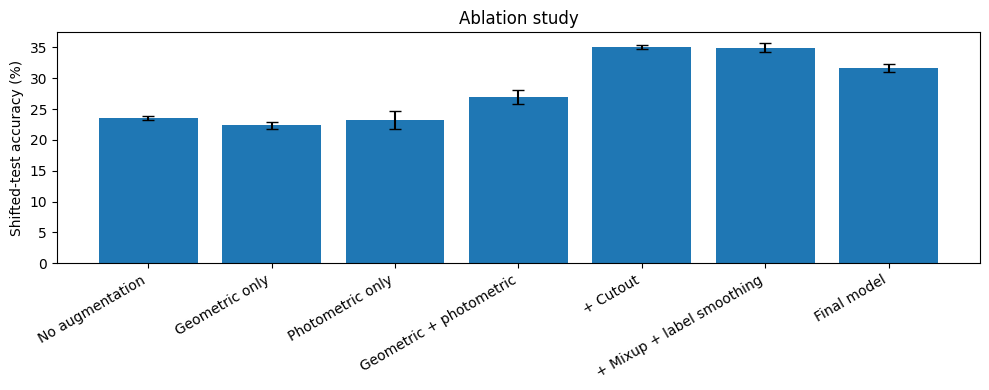

In [118]:
means = [np.mean(np.array(r)[:, 2]) * 100 for r in ablation.values()]
stds  = [np.std(np.array(r)[:, 2]) * 100 for r in ablation.values()]

plt.figure(figsize=(10, 4))
plt.bar(range(len(means)), means, yerr=stds, capsize=4)
plt.xticks(range(len(means)), ablation.keys(), rotation=30, ha='right')
plt.ylabel('Shifted-test accuracy (%)')
plt.title('Ablation study')
plt.tight_layout(); plt.show()

# Part E

In [119]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

final_cfg = configs['+ Mixup + label smoothing']
final_models = []

for seed in [42, 43, 44]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    lr = keras.optimizers.schedules.CosineDecay(1e-3, EPOCHS * (400 // BATCH))
    model = build_model_c()
    model.compile(optimizer=keras.optimizers.AdamW(lr, weight_decay=5e-4),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
                  metrics=['accuracy'])
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    model.fit(make_data(final_cfg), validation_data=(x_val, tf.one_hot(y_val, 10)),
              epochs=EPOCHS, callbacks=[stop], verbose=0)
    final_models.append(model)
    print("seed", seed, "done")

seed 42 done
seed 43 done
seed 44 done


In [120]:
model = final_models[0]
pred_shift = model.predict(x_shifted, batch_size=1000, verbose=0).argmax(1)
pred_clean = model.predict(x_test, batch_size=1000, verbose=0).argmax(1)

In [121]:
rows = []
for c in range(10):
    mask = y_test == c
    rows.append([class_names[c],
                 round((pred_clean[mask] == c).mean() * 100, 1),
                 round((pred_shift[mask] == c).mean() * 100, 1)])

display(pd.DataFrame(rows, columns=['Class', 'Clean Test %', 'Shifted Test %']))

,Class,Clean Test %,Shifted Test %
0,airplane,37.9,10.9
1,automobile,60.3,29.6
2,bird,48.6,33.8
3,cat,18.2,20.1
4,deer,12.2,31.9
5,dog,2.2,0.9
6,frog,58.8,30.8
7,horse,62.7,47.9
8,ship,61.1,54.3
9,truck,13.4,5.1


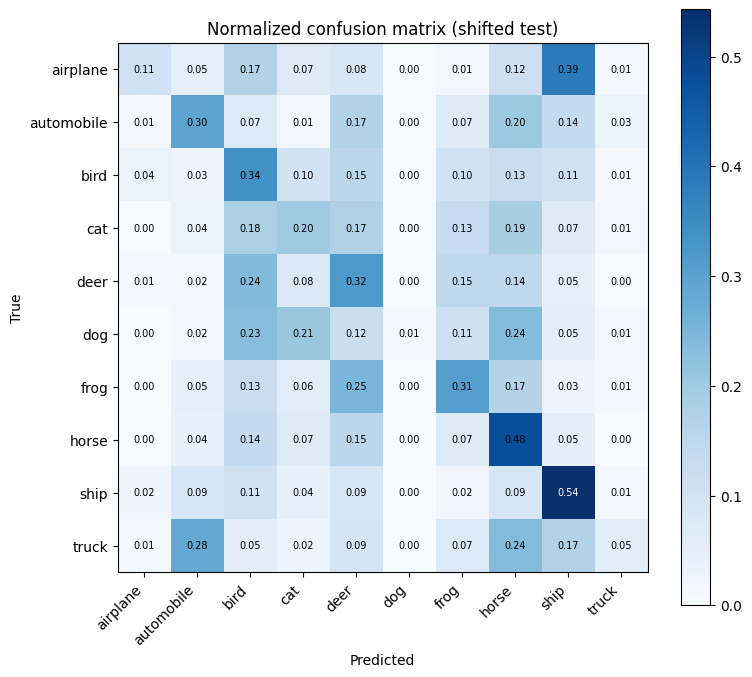

In [122]:
cm = np.zeros((10, 10))
for t, p in zip(y_test, pred_shift):
    cm[t, p] += 1
cm = cm / cm.sum(axis=1, keepdims=True)       # each row sums to 1

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha='right')
plt.yticks(range(10), class_names)
for i in range(10):
    for j in range(10):
        plt.text(j, i, f"{cm[i, j]:.2f}", ha='center', va='center',
                 color='white' if cm[i, j] > 0.5 else 'black', fontsize=7)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Normalized confusion matrix (shifted test)')
plt.tight_layout(); plt.show()

In [123]:
pairs = []
for i in range(10):
    for j in range(10):
        if i != j:
            pairs.append((cm[i, j], class_names[i], class_names[j]))

pairs.sort(reverse=True)
for rate, true_c, pred_c in pairs[:6]:
    print(f"{true_c:11s} predicted as {pred_c:11s}: {rate*100:.1f}% of {true_c} images")

airplane    predicted as ship       : 38.6% of airplane images
truck       predicted as automobile : 28.3% of truck images
frog        predicted as deer       : 25.2% of frog images
deer        predicted as bird       : 24.1% of deer images
truck       predicted as horse      : 23.9% of truck images
dog         predicted as horse      : 23.9% of dog images


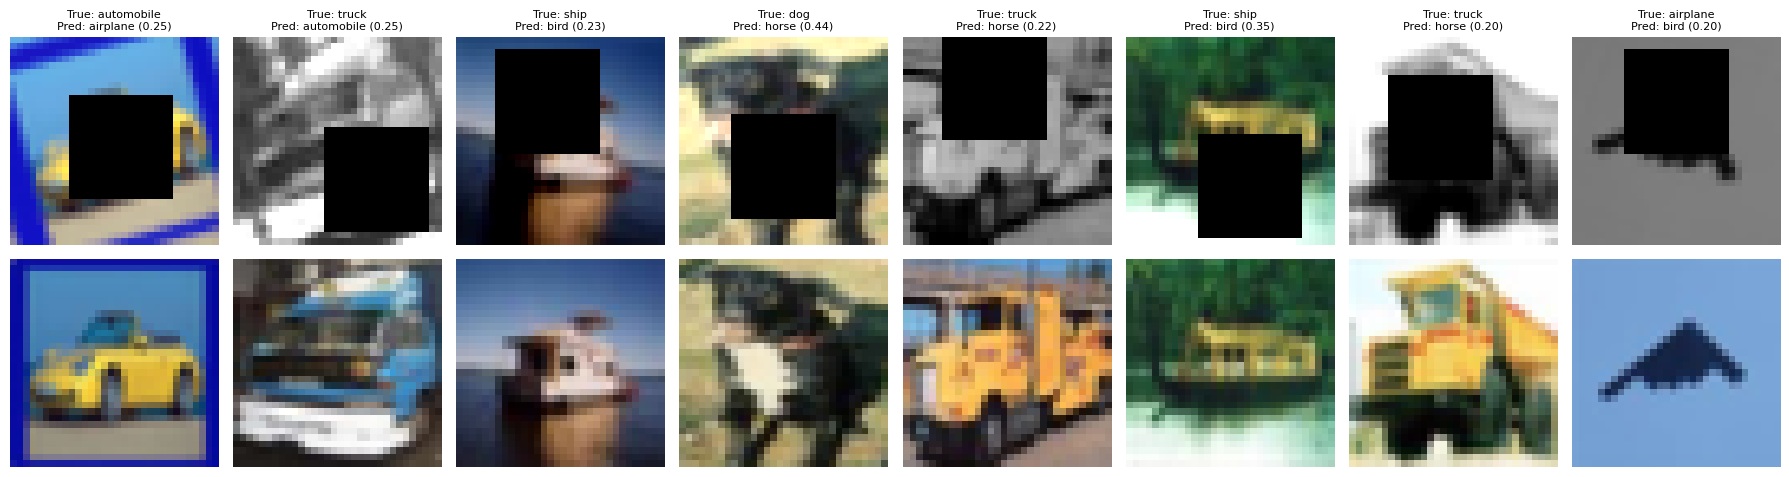

In [124]:
wrong = np.where(pred_shift != y_test)[0]
chosen = np.random.default_rng(0).choice(wrong, 8, replace=False)

probs = model.predict(x_shifted[chosen], verbose=0)

fig, ax = plt.subplots(2, 8, figsize=(18, 5))
for k, i in enumerate(chosen):
    ax[0, k].imshow(x_shifted[i]); ax[0, k].axis('off')
    ax[0, k].set_title(f"True: {class_names[y_test[i]]}\nPred: {class_names[pred_shift[i]]} ({probs[k].max():.2f})",
                       fontsize=8)
    ax[1, k].imshow(x_test[i]); ax[1, k].axis('off')
ax[0, 0].set_ylabel("Shifted"); ax[1, 0].set_ylabel("Clean")
plt.tight_layout(); plt.show()

In [125]:
x_gray = np.repeat(x_test.mean(axis=-1, keepdims=True), 3, axis=-1)    # every image grayscale

clean_accs, gray_accs = [], []
for m in final_models:
    clean_accs.append(accuracy(m, x_test, y_test) * 100)
    gray_accs.append(accuracy(m, x_gray, y_test) * 100)

print(f"Final model, clean test:          {np.mean(clean_accs):.2f} ± {np.std(clean_accs):.2f}")
print(f"Final model, clean test + gray:   {np.mean(gray_accs):.2f} ± {np.std(gray_accs):.2f}")

Final model, clean test:          41.96 ± 3.13
Final model, clean test + gray:   38.78 ± 3.12


In [126]:
keras.backend.clear_session()
keras.utils.set_random_seed(42)

base = build_model()
base.compile(optimizer=keras.optimizers.Adam(1e-3),
             loss='sparse_categorical_crossentropy', metrics=['accuracy'])
base.fit(x_tr, y_tr, epochs=60, batch_size=16, verbose=0)

print(f"Baseline, clean test:        {accuracy(base, x_test, y_test)*100:.2f}")
print(f"Baseline, clean test + gray: {accuracy(base, x_gray, y_test)*100:.2f}")

Baseline, clean test:        41.95
Baseline, clean test + gray: 32.87


## Part F

In [127]:
tta_shift = layers.RandomTranslation(0.06, 0.06, fill_mode='reflect')

def tta_copy(x, flip_it):
    if flip_it:
        x = x[:, :, ::-1, :]                       # horizontal flip
    return tta_shift(x, training=True).numpy()     # small random shift

In [128]:
def predict_tta(model, x, n):
    probs = model.predict(x, batch_size=1000, verbose=0)           # copy 1: the original image
    for k in range(n - 1):
        xa = tta_copy(x, flip_it=(k % 2 == 0))                     # alternate flipped / not flipped
        probs += model.predict(xa, batch_size=1000, verbose=0)
    return probs / n

In [129]:
import time

N_VALUES = [1, 5, 10, 20]
tta_results = {n: [] for n in N_VALUES}
tta_time = {n: [] for n in N_VALUES}

for m in final_models:
    for n in N_VALUES:
        keras.utils.set_random_seed(0)
        start = time.time()
        p = predict_tta(m, x_shifted, n)
        tta_time[n].append(time.time() - start)
        tta_results[n].append((p.argmax(1) == y_test).mean() * 100)

In [130]:
rows = []
base_time = np.mean(tta_time[1])
for n in N_VALUES:
    acc = np.array(tta_results[n])
    rows.append([n,
                 f"{acc.mean():.2f} ± {acc.std():.2f}",
                 f"{acc.mean() - np.mean(tta_results[1]):+.2f}",
                 f"{np.mean(tta_time[n]):.2f}",
                 f"{np.mean(tta_time[n]) / base_time:.1f}x"])

display(pd.DataFrame(rows, columns=['N copies', 'Shifted Test Acc %', 'Change vs N=1 (pts)',
                                    'Inference time (s, 10k images)', 'Cost vs N=1']))

,N copies,Shifted Test Acc %,Change vs N=1 (pts),"Inference time (s, 10k images)",Cost vs N=1
0,1,30.85 ± 3.07,+0.00,0.71,1.0x
1,5,30.15 ± 3.30,-0.70,4.36,6.1x
2,10,29.99 ± 3.38,-0.86,8.96,12.6x
3,20,30.06 ± 3.40,-0.78,18.04,25.3x


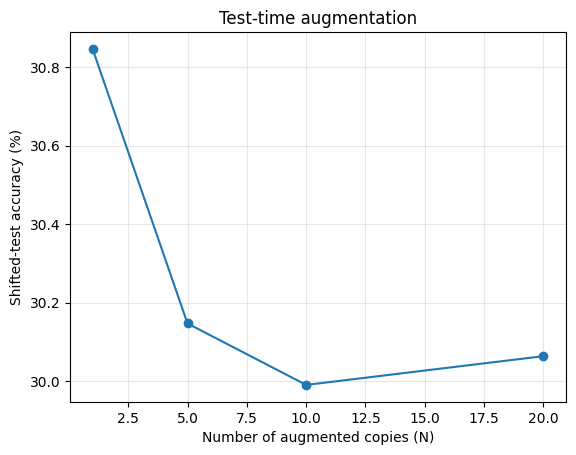

In [131]:
means = [np.mean(tta_results[n]) for n in N_VALUES]
plt.plot(N_VALUES, means, marker='o')
plt.xlabel('Number of augmented copies (N)')
plt.ylabel('Shifted-test accuracy (%)')
plt.title('Test-time augmentation')
plt.grid(alpha=0.3)
plt.show()